In [35]:
import torch as torch
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F

from sklearn.datasets import load_sample_images
from torch import  nn


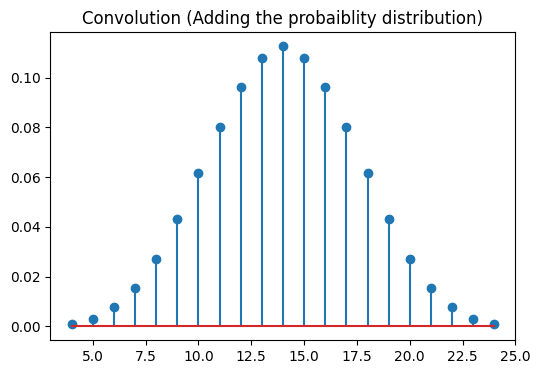

In [92]:
X = np.ones(6)/6
y = np.convolve(np.convolve(X, X), np.convolve(X, X))
plt.figure(figsize=(6, 4))
plt.title('Convolution (Adding the probaiblity distribution)')
plt.stem(range(4, 25), y)
plt.show()

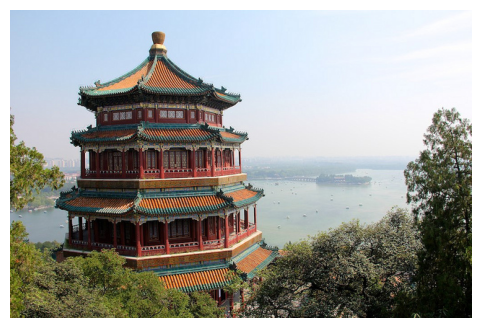

In [94]:
X = load_sample_images()['images'][0]
plt.figure(figsize=(6, 4))
plt.imshow(X)
plt.axis('off')
plt.show()

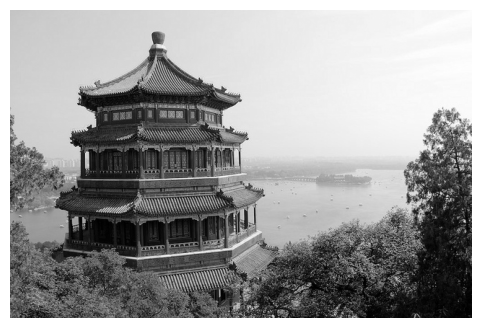

In [95]:
R = X[:, :, 0]
G = X[:, :, 1]
B = X[:, :, 2]

X_gray = 0.2989 * R + 0.5870 * G + 0.1140 * B
plt.figure(figsize=(6, 4))
plt.imshow(X_gray, cmap='gray')
plt.axis('off')
plt.show()

In [96]:
kernel = torch.tensor([
                      [-1, -1, -1],
                      [-1, 8, -1],
                      [-1, -1, -1]], dtype=torch.float).view(1, 1, 3, 3)
X_gray = torch.tensor(X_gray, dtype=torch.float).view(1, 1, 427, 640)
X_gray.shape

torch.Size([1, 1, 427, 640])

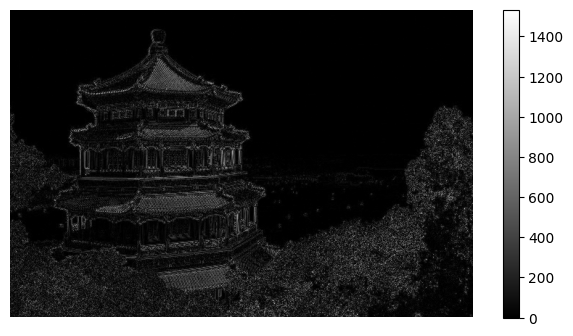

In [97]:
conv = F.conv2d(input=X_gray, weight=kernel)
conv = conv
plt.figure(figsize=(8, 4))
plt.imshow(conv[0, 0].abs(), cmap='gray')
plt.colorbar()
plt.axis('off')
plt.show()

A kernel sum = 0 detects the edges

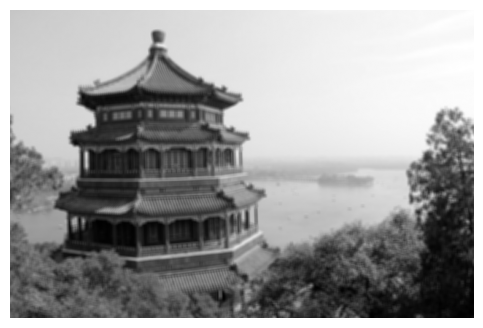

In [81]:
kernel = torch.ones(size=(5, 5), dtype=torch.float).view(1, 1, 5, 5)
kernel = kernel / kernel.sum()
conv = F.conv2d(input=X_gray, weight=kernel)
plt.figure(figsize=(6, 4))
plt.imshow(conv[0, 0], cmap='gray')
plt.axis('off')
plt.show()

Kernel sum = 1 blurs the image, it is moving average of nearby pixels

In [98]:
conv.shape, X_gray.shape

(torch.Size([1, 1, 425, 638]), torch.Size([1, 1, 427, 640]))

2 rows and columns are lost, because kernel central pixel decides the new pixel value after the convolution, so kernel starts with 1 row and column off and ends in the same way so that's why they are lost

In [99]:
X.shape

(427, 640, 3)

In [104]:
X_tensor = torch.permute(torch.tensor(X, dtype=torch.float), [2, 0, 1])

In [140]:
kernel = torch.tensor([
                      [-1, -1, -1],
                      [-1, 8, -1],
                      [-1, -1, -1]], dtype=torch.float)

In [141]:
kernel = torch.stack((kernel, kernel, kernel)).unsqueeze(0)
kernel.shape, kernel

(torch.Size([1, 3, 3, 3]),
 tensor([[[[-1., -1., -1.],
           [-1.,  8., -1.],
           [-1., -1., -1.]],
 
          [[-1., -1., -1.],
           [-1.,  8., -1.],
           [-1., -1., -1.]],
 
          [[-1., -1., -1.],
           [-1.,  8., -1.],
           [-1., -1., -1.]]]]))

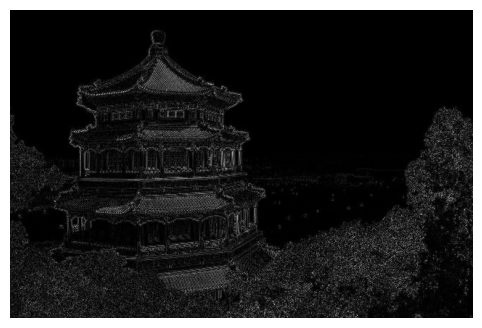

In [135]:
conv = F.conv2d(input=X_tensor, weight=kernel)
conv = torch.permute(conv, [1, 2, 0])
plt.figure(figsize=(6, 4))
plt.imshow(conv.abs(), cmap='gray')
plt.axis('off')
plt.show()

In the above convolution i did 2d convolution for each channel seperately and the scalars that got from each channel are added so they provided one scalar which reduces the dimension to 2d.

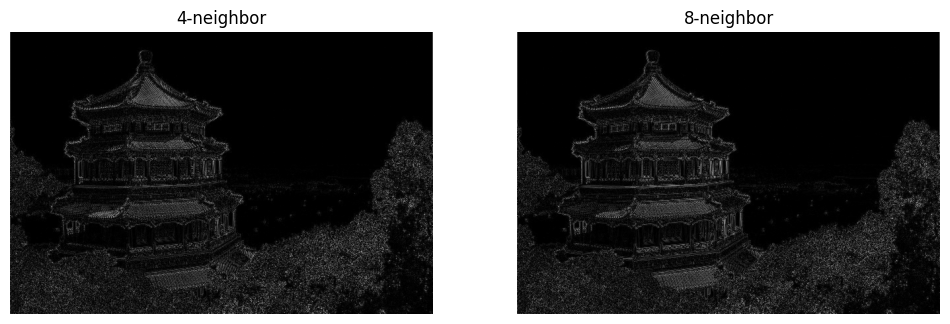

In [137]:
k4 = torch.tensor([[0, -1, 0],
                   [-1, 4, -1],
                   [0, -1, 0]], dtype=torch.float).view(1, 1, 3, 3)

k8 = torch.tensor([[-1, -1, -1],
                   [-1,  8, -1],
                   [-1, -1, -1]], dtype=torch.float).view(1, 1, 3, 3)

out4 = F.conv2d(X_gray, k4, padding=1)
out8 = F.conv2d(X_gray, k8, padding=1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(out4[0, 0].abs(), cmap='gray'); ax[0].set_title('4-neighbor')
ax[1].imshow(out8[0, 0].abs(), cmap='gray'); ax[1].set_title('8-neighbor')
for a in ax: a.axis('off')
plt.show()